# **OOD Scores Comparison**

This notebook focuses on conducting comparative experiments between **In-Distribution (ID)** and **Out-of-Distribution (OOD)** class pairs to evaluate detection performance. Our primary objective is to analyze and visualize how various scoring mechanisms distinguish between known and unknown data distributions.

We will be evaluating several state-of-the-art post-hoc methods, including:
* **ODIN** (Out-of-DIstribution detector for Neural networks)
* **Energy-based Scoring**
* **Calibrated OOD Detection**
* And other baseline metrics.

For these experiments, we will utilize **Meta’s DINOv3** as our backbone model to extract high-quality features and compute the necessary decision scores.

---

<div align="center">
    <img src="https://i0.wp.com/spotintelligence.com/wp-content/uploads/2024/11/out-of-distribution.jpg?resize=1024%2C576&ssl=1" alt="Out-of-Distribution Visualization" width="80%">
    <p><em>Visual representation of the separation between In-Distribution and Out-of-Distribution samples.</em></p>
</div>

---

## **0. Notebook Setup**

### **Imports**


In [107]:
import torch
import numpy as np
import torchvision
from transformers import AutoImageProcessor, AutoModel
from torch.utils.data import DataLoader, TensorDataset
import h5py
import random
import kagglehub
import os
from torchvision.datasets import Food101, OxfordIIITPet, FGVCAircraft
from torchvision import transforms
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import roc_auc_score, roc_curve

We will be using `pytorch-ood` library a standard framework in OOD research that includes auto-downloaders.




In [ ]:
!pip install pytorch-ood

In [84]:
from pytorch_ood.dataset.img import Textures

### **Model Preparation**

In [85]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [86]:
from huggingface_hub import login
login()

In [87]:
model_name = "facebook/dinov3-vit7b16-pretrain-lvd1689m"

print(f"Loading flagship model: {model_name}")
print(f"Targeting Architecture: 40 Layers, 4096 Embedding Dim")

if 'dtype' not in locals():
    dtype = torch.float16 if torch.cuda.is_available() else torch.float32

try:
    #Load Model with Memory Optimization and Eager Attention
    # We strictly need eager attention to capture the attention weights
    model = AutoModel.from_pretrained(
        model_name,
        torch_dtype=dtype,
        low_cpu_mem_usage=True,
        attn_implementation="eager"
    ).to(device).eval()

    #Load Processor
    processor = AutoImageProcessor.from_pretrained(model_name)

    num_registers = getattr(model.config, "num_register_tokens", 4)
    print(f"Model loaded. Number of register tokens identified: {num_registers}")

    transform = lambda img: processor(images=img, return_tensors="pt")['pixel_values'].squeeze()

    #Verify Layer Count
    if hasattr(model, "vision_model"):
        num_layers = len(model.vision_model.encoder.layers)
    else:
        #Fallback for flat architectures
        num_layers = len(model.layer)

    print(f"Success! Model loaded with {num_layers} layers.")

except Exception as e:
    print(f"Error loading model: {e}")
    print("Tip: If you run out of memory (OOM), try 'dinov3-vitl16' (Large, 24 layers) instead.")

Loading flagship model: facebook/dinov3-vit7b16-pretrain-lvd1689m
Targeting Architecture: 40 Layers, 4096 Embedding Dim


Loading weights:   0%|          | 0/687 [00:00<?, ?it/s]

Model loaded. Number of register tokens identified: 4
Success! Model loaded with 40 layers.


## **1. Datasets**
For our experiment we will be using `Food101` as our ID dataset.
To compare we will be using `OxfordIIITPet`, `Textures` and `FGVCAircraft-o`.

We will also be using a 512x512 pipeline instead of 224x224 like we did before. This will take a significant toll on VRAM so we will be decreasing `batch-size` as needed.

In [88]:
high_res_transform = transforms.Compose([
    transforms.Resize(512),         # Scale the shorter edge to 512
    transforms.CenterCrop(512),     # Crop the center to make it exactly 512x512
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [22]:
print("Downloading ID Dataset: Food-101...")
id_dataset = Food101(root='./data/food101', split='test', download=True, transform=high_res_transform)

print("Downloading Far-OOD Dataset: Oxford-IIIT Pets...")
pets_dataset = OxfordIIITPet(root='./data/pets', split='test', download=True, transform=high_res_transform)

print("Downloading Far-OOD Dataset: FGVC Aircraft...")
aircraft_dataset = FGVCAircraft(root='./data/aircraft', split='test', download=True, transform=high_res_transform)

print("Downloading Far-OOD Dataset: Textures...")
textures_dataset = Textures(root='./data/textures', download=True, transform=high_res_transform)

100%|██████████| 5.00G/5.00G [06:15<00:00, 13.3MB/s]


100%|██████████| 792M/792M [00:44<00:00, 17.8MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.1MB/s]


100%|██████████| 2.75G/2.75G [03:00<00:00, 15.2MB/s]


In [23]:
batch_size = 16
num_workers = 4

id_loader = DataLoader(id_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
pets_loader = DataLoader(pets_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
aircraft_loader = DataLoader(aircraft_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
textures_loader = DataLoader(textures_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)

print("-" * 30)
print(f"✅ Success! All datasets downloaded and loaded.")
print(f"ID (Food-101) samples: {len(id_dataset)}")
print(f"OOD (Pets) samples: {len(pets_dataset)}")
print(f"OOD (Aircraft) samples: {len(aircraft_dataset)}")
print(f"OOD (Textures) samples: {len(textures_dataset)}")

------------------------------
✅ Success! All datasets downloaded and loaded.
ID (Food-101) samples: 25250
OOD (Pets) samples: 3669
OOD (Aircraft) samples: 3333
OOD (Textures) samples: 5640


## **2. Extracting Features and Saving them**

In [26]:
def extract_and_save_features(model, dataloader, device, save_path):
    """
    Passes a dataloader through DINOv3, extracts the [CLS] token,
    and saves the features and labels to disk.
    """
    # Ensure the model is in evaluation mode
    model.eval()

    all_features = []
    all_labels = []

    print(f"Extracting features to save at: {save_path}")

    # torch.no_grad() is CRITICAL here. It tells PyTorch not to track gradients,
    # which saves massive amounts of VRAM and speeds up inference.
    with torch.no_grad():
        for images, labels in tqdm(dataloader, desc="Processing Batches"):
            images = images.to(device)

            # 1. Pass images through DINOv3
            outputs = model(images)

            # 2. Extract the [CLS] token.
            # outputs.last_hidden_state shape is (batch_size, num_patches + 1, embedding_dim)
            # The [CLS] token is always at index 0 of the sequence dimension.
            cls_tokens = outputs.last_hidden_state[:, 0, :]

            # Move to CPU to prevent GPU RAM overflow, and store in our lists
            all_features.append(cls_tokens.cpu())
            all_labels.append(labels)

    # Concatenate all batches into one giant tensor
    all_features = torch.cat(all_features, dim=0)
    all_labels = torch.cat(all_labels, dim=0)

    # Create directory if it doesn't exist
    os.makedirs(os.path.dirname(save_path), exist_ok=True)

    # Save to disk
    torch.save({'features': all_features, 'labels': all_labels}, save_path)
    print(f"Saved {all_features.shape[0]} features of dimension {all_features.shape[1]}!")

In [ ]:
extract_and_save_features(model, id_loader, device, "./extracted_features/id_food101.pt")

In [ ]:
extract_and_save_features(model, pets_loader, device, "./extracted_features/ood_pets.pt")
extract_and_save_features(model, aircraft_loader, device, "./extracted_features/ood_aircraft.pt")
extract_and_save_features(model, textures_loader, device, "./extracted_features/ood_textures.pt")

### **3. Creating pairs**

In [89]:
def unnormalize(tensor):
  mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
  std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

  tensor = tensor * std + mean
  return torch.clamp(tensor, 0, 1)

In [90]:
def get_image(dataset, target_class=None, sample_idx=0):
    """
    Searches a dataset for a specific class.
    If the dataset is an OOD wrapper without classes, it just returns an image by index.
    """
    # Fallback for pytorch_ood datasets (like Textures) that strip class names
    if not hasattr(dataset, 'classes') or target_class is None:
        img_tensor, _ = dataset[sample_idx]
        return img_tensor

    if target_class not in dataset.classes:
        raise ValueError(f"Class '{target_class}' not found! Available examples: {dataset.classes[:5]}")

    class_idx = dataset.classes.index(target_class)

    # Extract labels based on how the dataset stores them
    labels = getattr(dataset, 'targets', getattr(dataset, '_labels', None))

    if labels is not None:
        matching_indices = [i for i, label in enumerate(labels) if label == class_idx]
    else:
        # Slow fallback if labels are hidden
        matching_indices = [i for i, (_, label) in enumerate(dataset) if label == class_idx]

    img_tensor, _ = dataset[matching_indices[sample_idx]]
    return img_tensor

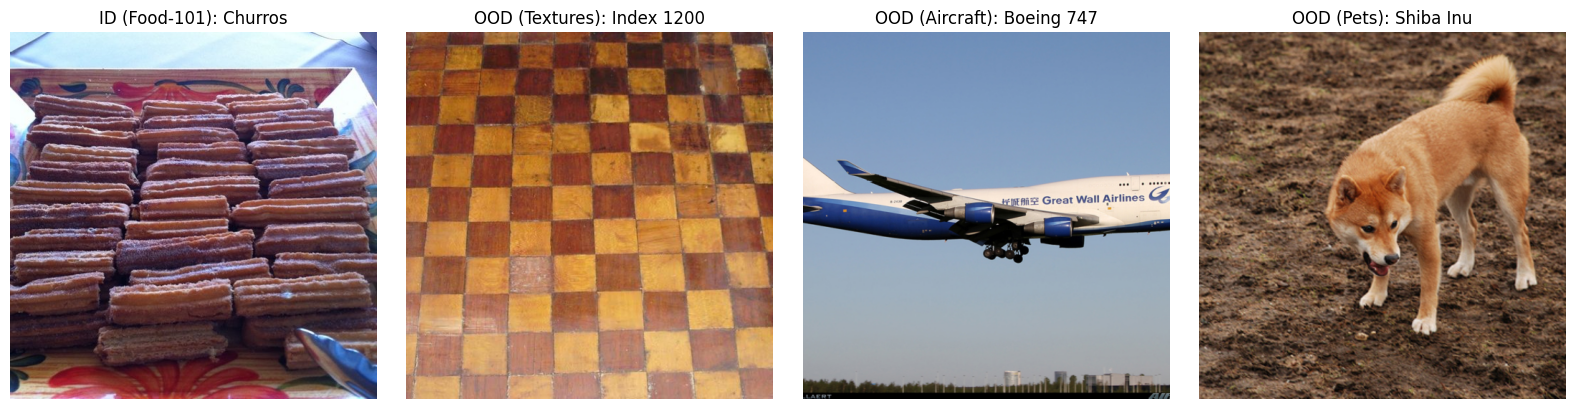

In [91]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

# 1. Grab a 'churros' from Food-101 (ID)
churro_img = get_image(id_dataset, 'churros', sample_idx=0)
axes[0].imshow(unnormalize(churro_img).permute(1, 2, 0))
axes[0].set_title("ID (Food-101): Churros")
axes[0].axis('off')

# 2. Grab a texture from Textures (OOD)
texture_idx = 1200
texture_img = get_image(textures_dataset, target_class=None, sample_idx=texture_idx)
axes[1].imshow(unnormalize(texture_img).permute(1, 2, 0))
axes[1].set_title(f"OOD (Textures): Index {texture_idx}")
axes[1].axis('off')

# 3. Grab a '747-400' from Aircraft
aircraft_img = get_image(aircraft_dataset, '747-400', sample_idx=0)
axes[2].imshow(unnormalize(aircraft_img).permute(1, 2, 0))
axes[2].set_title("OOD (Aircraft): Boeing 747")
axes[2].axis('off')

# 4. Grab a 'shiba_inu' from Pets
dog_img = get_image(pets_dataset, 'Shiba Inu', sample_idx=2)
axes[3].imshow(unnormalize(dog_img).permute(1, 2, 0))
axes[3].set_title("OOD (Pets): Shiba Inu")
axes[3].axis('off')

plt.tight_layout()
plt.show()

### **4. Training a Linear Probe**

In [92]:
print("Loading saved Food-101 features...")
id_data = torch.load("./extracted_features/id_food101.pt")
id_features = id_data['features']
id_labels = id_data['labels']

Loading saved Food-101 features...


In [93]:
feature_dataset = TensorDataset(id_features, id_labels)
feature_loader = DataLoader(feature_dataset, batch_size=256, shuffle=True)

In [94]:
class LinearProbe(nn.Module):
    def __init__(self, input_dim=4096, num_classes=101):
        super(LinearProbe, self).__init__()
        self.fc = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        return self.fc(x)

In [95]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
classifier = LinearProbe(input_dim=id_features.shape[1], num_classes=101).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(classifier.parameters(), lr=0.001)

In [96]:
epochs = 10
print("Training Linear Probe...")

for epoch in range(epochs):
    classifier.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for feats, labels in feature_loader:
        feats = feats.to(device, dtype=torch.float32)
        labels = labels.to(device)

        # Zero the gradients
        optimizer.zero_grad()

        # Forward pass: get logits
        logits = classifier(feats)

        # Calculate loss
        loss = criterion(logits, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Track accuracy and loss
        running_loss += loss.item() * feats.size(0)
        _, predicted = torch.max(logits, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = 100 * correct / total
    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f} - Accuracy: {epoch_acc:.2f}%")

print("Training Complete! The classifier is ready.")

Training Linear Probe...
Epoch [1/10] - Loss: 0.6296 - Accuracy: 91.94%
Epoch [2/10] - Loss: 0.1429 - Accuracy: 96.57%
Epoch [3/10] - Loss: 0.1020 - Accuracy: 97.59%
Epoch [4/10] - Loss: 0.0782 - Accuracy: 98.11%
Epoch [5/10] - Loss: 0.0613 - Accuracy: 98.62%
Epoch [6/10] - Loss: 0.0498 - Accuracy: 98.97%
Epoch [7/10] - Loss: 0.0403 - Accuracy: 99.22%
Epoch [8/10] - Loss: 0.0337 - Accuracy: 99.37%
Epoch [9/10] - Loss: 0.0287 - Accuracy: 99.51%
Epoch [10/10] - Loss: 0.0245 - Accuracy: 99.65%
Training Complete! The classifier is ready.


## **5. Generating Energy score**

## The Energy Score Math

In standard classification, models use the **Softmax function**, which forces all probabilities to sum up to 1. This is dangerous for OOD (Out-of-Distribution) detection because the model is forced to be overly confident even if it has never seen the image before.

Energy-based scoring bypasses this by looking at the raw, un-squashed logits $f_i(x)$ across all $C$ classes. The formula calculates the "Energy" $E(x;f)$ of an image:

$$E(x; f) = -T \log \sum_{i=1}^{C} e^{f_i(x) / T}$$

> **Note:** In this equation, $T$ represents the temperature parameter. Higher energy values typically correlate with lower likelihood that the data belongs to the training distribution.

### **5.1 Functions and calculation**

In [97]:
model.eval()
classifier.eval()

LinearProbe(
  (fc): Linear(in_features=4096, out_features=101, bias=True)
)

In [98]:
def get_energy_score(img_tensor, T=1.0):
    """
    Passes a single image tensor through DINO and the Linear Probe,
    then calculates the Energy Score.
    """
    with torch.no_grad():
        # 1. Add a batch dimension: [3, 512, 512] -> [1, 3, 512, 512]
        img_batch = img_tensor.unsqueeze(0).to(device)

        # 2. Extract DINO feature ([CLS] token)
        outputs = model(img_batch)
        # Ensure we cast back to float32 to match the Linear Probe!
        feature = outputs.last_hidden_state[:, 0, :].to(device, dtype=torch.float32)

        # 3. Get Logits from the Linear Probe
        logits = classifier(feature)

        # 4. Calculate Energy Score
        # E(x) = -T * log(sum(exp(logits / T)))
        # Note: We use torch.logsumexp instead of doing it manually.
        # Manual exp() can cause numerical overflow (Infinity) with large logits!
        energy = -T * torch.logsumexp(logits / T, dim=1)

    return energy.item()

In [101]:
def get_dataset_energy(features_path, classifier, device, T=1.0):
    """
    Loads saved features, gets logits from the classifier, and computes Energy.
    Standard OOD convention: We use Negative Energy so that ID data has
    *higher* scores and OOD data has *lower* scores.
    """
    data = torch.load(features_path)
    features = data['features'].to(device, dtype=torch.float32)

    classifier.eval()
    with torch.no_grad():
        logits = classifier(features)
        # Energy = -T * logsumexp(logits / T)
        # We return the NEGATIVE energy so ID > OOD (required for AUROC math)
        energy = T * torch.logsumexp(logits / T, dim=1)

    return energy.cpu().numpy()

In [99]:
print("-" * 40)
print("Evaluating Specific Candidates:")
print("-" * 40)

# Calculate and print the scores
score_id = get_energy_score(churro_img)
score_ood_texture = get_energy_score(texture_img)
score_ood_aircraft = get_energy_score(aircraft_img)
score_ood_dog = get_energy_score(dog_img)

print(f"Energy Score [ID - Churro]:      {score_id:.4f}")
print(f"Energy Score [OOD - Texture]:    {score_ood_texture:.4f}")
print(f"Energy Score [OOD - Aircraft]:   {score_ood_aircraft:.4f}")
print(f"Energy Score [OOD - Dog]:        {score_ood_dog:.4f}")

----------------------------------------
Evaluating Specific Candidates:
----------------------------------------
Energy Score [ID - Churro]:      -14.9788
Energy Score [OOD - Texture]:    -4.7727
Energy Score [OOD - Aircraft]:   -4.7960
Energy Score [OOD - Dog]:        -4.8156


### **5.2 AUROC**
AUROC (Area Under the Receiver Operating Characteristic curve) measures a classification model's ability to distinguish between two classes (e.g., Spam vs. Not Spam).

### *ROC Curve*
The curve plots two metrics as you move the classification threshold from 0 to 1:


*   True Positive Rate (Sensitivity)
*   False Positive Rate (1 - Specificity)



In [102]:
def calculate_roc(id_scores, ood_scores):
    # Create labels: 1 for ID, 0 for OOD
    y_true = np.concatenate([np.ones(len(id_scores)), np.zeros(len(ood_scores))])
    y_scores = np.concatenate([id_scores, ood_scores])

    # Calculate AUROC
    auroc = roc_auc_score(y_true, y_scores)
    # Get Curve Data
    fpr, tpr, _ = roc_curve(y_true, y_scores)
    return auroc, fpr, tpr

In [106]:
print("Computing Energy Scores across all datasets...")

from sklearn.metrics import roc_auc_score, roc_curve
id_scores = get_dataset_energy("./extracted_features/id_food101.pt", classifier, device)

ood_pets_scores = get_dataset_energy("./extracted_features/ood_pets.pt", classifier, device)
ood_aircraft_scores = get_dataset_energy("./extracted_features/ood_aircraft.pt", classifier, device)
ood_textures_scores = get_dataset_energy("./extracted_features/ood_textures.pt", classifier, device)


# Calculate everything
auroc_pets, fpr_pets, tpr_pets = calculate_roc(id_scores, ood_pets_scores)
auroc_aircraft, fpr_air, tpr_air = calculate_roc(id_scores, ood_aircraft_scores)
auroc_textures, fpr_tex, tpr_tex = calculate_roc(id_scores, ood_textures_scores)

Computing Energy Scores across all datasets...


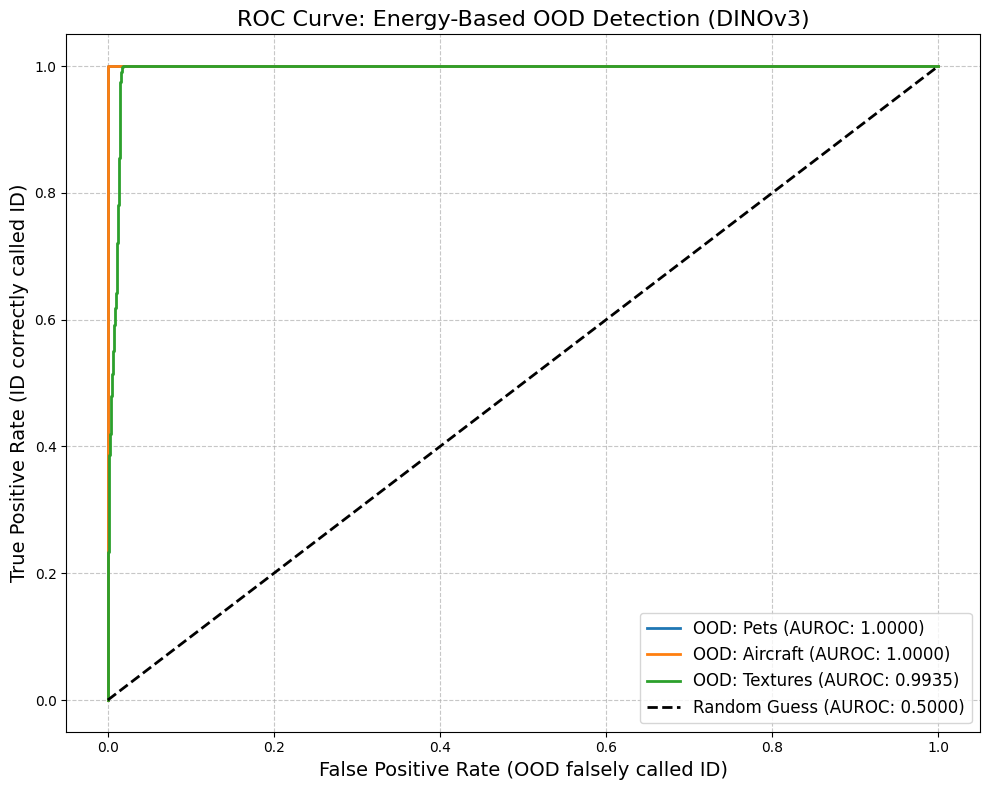

In [120]:
print("-" * 40)
print("FINAL ENERGY-BASED AUROC RESULTS:")
print("-" * 40)
print(f"Food-101 vs Pets:     {auroc_pets * 100:.2f}%")
print(f"Food-101 vs Aircraft: {auroc_aircraft * 100:.2f}%")
print(f"Food-101 vs Textures: {auroc_textures * 100:.2f}%")

----------------------------------------
FINAL ENERGY-BASED AUROC RESULTS:
----------------------------------------
Food-101 vs Pets:     100.00%
Food-101 vs Aircraft: 100.00%
Food-101 vs Textures: 99.35%


### **6.3 Getting the culprits**

Analyzing the Decision Boundary for OOD Textures...
Official Acceptance Threshold (95% TPR): 9.8920
Total Textures mistakenly accepted as Food: 84 out of 5640


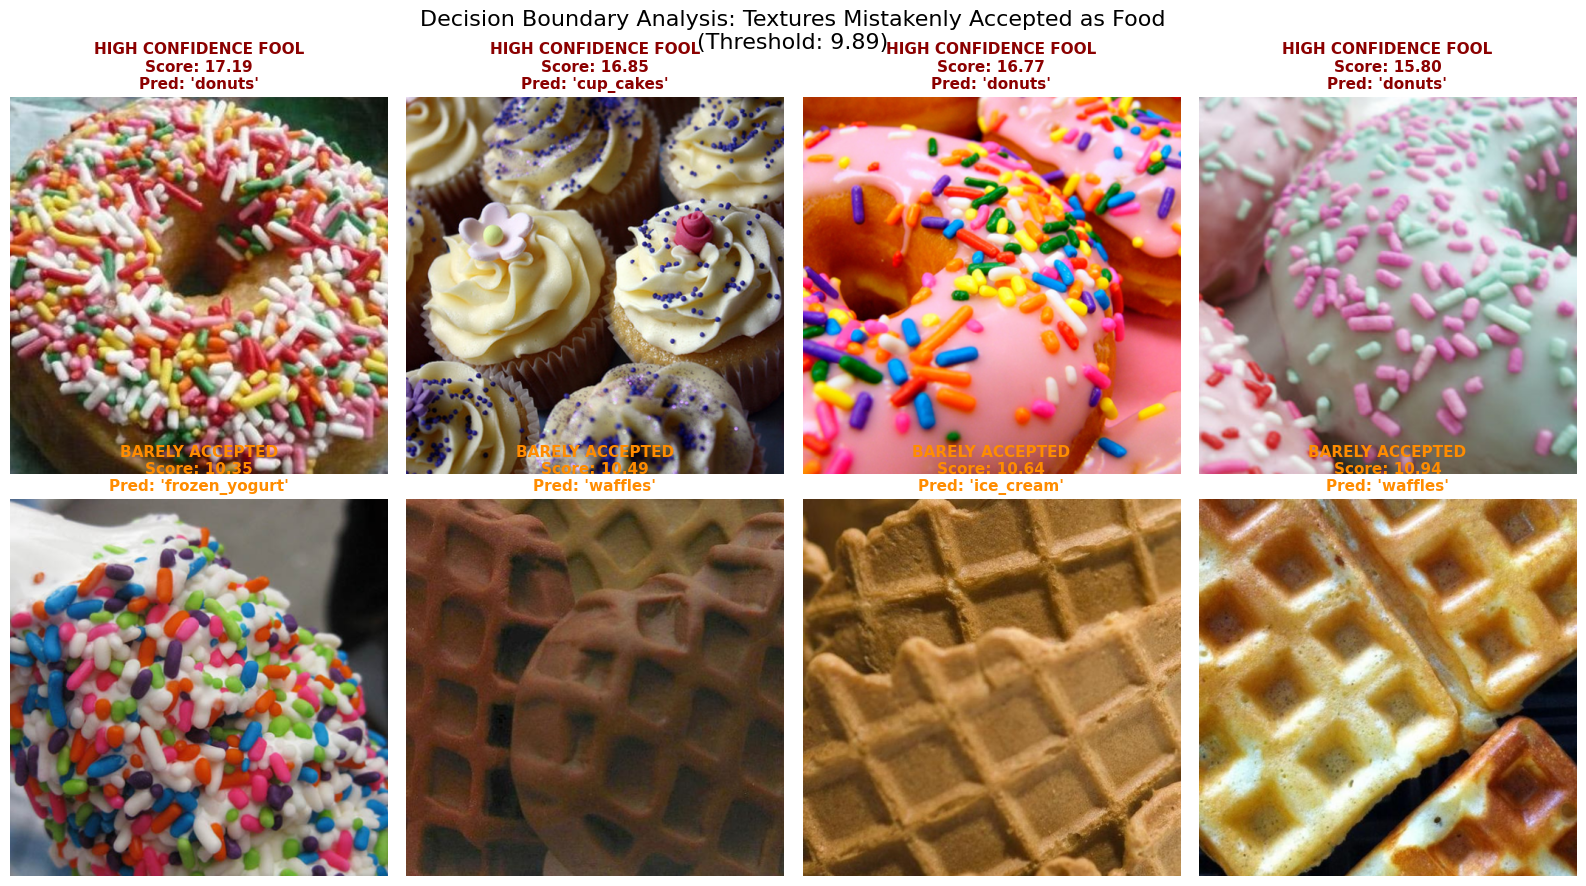

In [125]:
print("Analyzing the Decision Boundary for OOD Textures...")

# 1. Load ID features to establish the Official Threshold
id_data = torch.load("./extracted_features/id_food101.pt")
id_features = id_data['features'].to(device, dtype=torch.float32)

tex_data = torch.load("./extracted_features/ood_textures.pt")
tex_features = tex_data['features'].to(device, dtype=torch.float32)

classifier.eval()
with torch.no_grad():
    # Calculate scores for real Food
    id_logits = classifier(id_features)
    id_scores = torch.logsumexp(id_logits, dim=1)

    # Calculate the 95% TPR Threshold (The 5th percentile of ID scores)
    # Anything above this number is officially "Accepted as Food"
    threshold = torch.quantile(id_scores, 0.05).item()
    print(f"Official Acceptance Threshold (95% TPR): {threshold:.4f}")

    # Calculate scores for Textures
    tex_logits = classifier(tex_features)
    tex_scores = torch.logsumexp(tex_logits, dim=1)
    tex_preds = torch.argmax(tex_logits, dim=1)

# 2. Filter for Textures that were MISTAKENLY ACCEPTED (Score > Threshold)
accepted_mask = tex_scores > threshold
accepted_indices = torch.where(accepted_mask)[0]
accepted_scores = tex_scores[accepted_mask]
accepted_preds = tex_preds[accepted_mask]

print(f"Total Textures mistakenly accepted as Food: {len(accepted_indices)} out of {len(tex_scores)}")

if len(accepted_indices) == 0:
    print("No Textures were accepted! The model's separation is perfect at 95% TPR.")
else:
    # 3. Sort the ACCEPTED textures by their scores
    sorted_acc_scores, sort_idx = torch.sort(accepted_scores, descending=True)
    sorted_acc_indices = accepted_indices[sort_idx]
    sorted_acc_preds = accepted_preds[sort_idx]

    # Handle cases where less than 4 were accepted
    top_k = min(4, len(accepted_indices))

    # Top 4: Most confident among the accepted
    top_indices = sorted_acc_indices[:top_k].cpu().numpy()
    top_scores = sorted_acc_scores[:top_k].cpu().numpy()
    top_preds = sorted_acc_preds[:top_k].cpu().numpy()

    # Bottom 4: Lowest scoring among the accepted (The "Borderline" ones)
    # .flip(0) reverses so the absolute lowest accepted score shows up first
    bottom_indices = sorted_acc_indices[-top_k:].flip(0).cpu().numpy()
    bottom_scores = sorted_acc_scores[-top_k:].flip(0).cpu().numpy()
    bottom_preds = sorted_acc_preds[-top_k:].flip(0).cpu().numpy()

    # 4. Plot the results
    fig, axes = plt.subplots(2, 4, figsize=(16, 9))

    # If we only have 1 row (less than 4 accepted), axes indexing changes
    if top_k < 4:
         axes = np.atleast_2d(axes)

    # Row 1: The Worst Fools (Highest Accepted Scores)
    for i, (idx, score, pred_idx) in enumerate(zip(top_indices, top_scores, top_preds)):
        img_tensor, _ = textures_dataset[idx]
        pred_food_name = id_dataset.classes[pred_idx]

        axes[0, i].imshow(unnormalize(img_tensor).permute(1, 2, 0))
        axes[0, i].set_title(f"HIGH CONFIDENCE FOOL\nScore: {score:.2f}\nPred: '{pred_food_name}'",
                             fontsize=11, fontweight='bold', color='darkred')
        axes[0, i].axis('off')

    # Row 2: The Borderline Cases (Lowest Accepted Scores)
    for i, (idx, score, pred_idx) in enumerate(zip(bottom_indices, bottom_scores, bottom_preds)):
        img_tensor, _ = textures_dataset[idx]
        pred_food_name = id_dataset.classes[pred_idx]

        axes[1, i].imshow(unnormalize(img_tensor).permute(1, 2, 0))
        axes[1, i].set_title(f"BARELY ACCEPTED\nScore: {score:.2f}\nPred: '{pred_food_name}'",
                             fontsize=11, fontweight='bold', color='darkorange')
        axes[1, i].axis('off')

    # Hide any unused subplots if top_k < 4
    for i in range(top_k, 4):
        axes[0, i].axis('off')
        axes[1, i].axis('off')

    plt.suptitle(f"Decision Boundary Analysis: Textures Mistakenly Accepted as Food\n(Threshold: {threshold:.2f})", fontsize=16)
    plt.tight_layout()
    plt.show()

## **6. The Mahalanobis Distance**
Instead of using the Linear Probe (logits), this method looks directly at the raw 4096-dimensional `.pt` features we saved. It calculates the "center point" (mean) of every Food class and measures how far an unknown image is from those centers, accounting for the oval-shape of the data distribution (covariance)

In [112]:
#Reloading in case Google Colab runtime expired
print("1. Loading ID features to build Mahalanobis parameters...")
id_data = torch.load("./extracted_features/id_food101.pt")
X_id = id_data['features'].to(device, dtype=torch.float32)
y_id = id_data['labels'].to(device)

1. Loading ID features to build Mahalanobis parameters...


In [111]:
num_classes = 101
feature_dim = X_id.shape[1]

# Compute Class-Conditional Means
print("2. Computing class-conditional means...")
class_means = torch.zeros((num_classes, feature_dim), device=device)
for c in range(num_classes):
    class_samples = X_id[y_id == c]
    class_means[c] = class_samples.mean(dim=0)

2. Computing class-conditional means...


In [113]:
X_centered = X_id.clone()
for c in range(num_classes):
    X_centered[y_id == c] -= class_means[c]

# Covariance = (X_centered^T @ X_centered) / (N - 1)
cov_matrix = (X_centered.T @ X_centered) / (X_centered.shape[0] - 1)

# Add a tiny bit of noise (jitter) to the diagonal to prevent numerical instability
jitter = 1e-5 * torch.eye(feature_dim, device=device)
cov_matrix += jitter

print("4. Inverting 4096x4096 covariance matrix (this takes a few seconds)...")
precision_matrix = torch.linalg.inv(cov_matrix)
print("✅ Mahalanobis parameters successfully built!")

4. Inverting 4096x4096 covariance matrix (this takes a few seconds)...
✅ Mahalanobis parameters successfully built!


### **6.1 Function**

In [114]:
def get_mahalanobis_score(features_path):
    """Calculates the negative minimum Mahalanobis distance for a dataset."""
    data = torch.load(features_path)
    features = data['features'].to(device, dtype=torch.float32)

    scores = []
    # Process in batches to prevent GPU Out-Of-Memory errors during broadcasting
    batch_size = 512
    for i in range(0, features.shape[0], batch_size):
        batch_feats = features[i:i+batch_size] # Shape: (B, 4096)

        # Calculate difference between batch features and ALL class means
        # Resulting shape: (B, 101, 4096)
        diff = batch_feats.unsqueeze(1) - class_means.unsqueeze(0)

        # Efficient batched quadratic form: (x - u)^T * Sigma^-1 * (x - u)
        # 1. diff @ precision_matrix -> (B, 101, 4096)
        left_term = torch.matmul(diff, precision_matrix)

        # 2. Dot product with diff -> (B, 101)
        dists = (left_term * diff).sum(dim=-1)

        # Find the minimum distance (closest class)
        min_dists, _ = torch.min(dists, dim=1)

        # Append NEGATIVE distance so ID > OOD
        scores.append(-min_dists)

    return torch.cat(scores).cpu().numpy()

In [119]:
scores_id = get_mahalanobis_score("./extracted_features/id_food101.pt")
scores_pets = get_mahalanobis_score("./extracted_features/ood_pets.pt")
scores_aircraft = get_mahalanobis_score("./extracted_features/ood_aircraft.pt")
scores_textures = get_mahalanobis_score("./extracted_features/ood_textures.pt")

### **6.2 AUROC**

In [116]:
def calculate_roc(id_scores, ood_scores):
    y_true = np.concatenate([np.ones(len(id_scores)), np.zeros(len(ood_scores))])
    y_scores = np.concatenate([id_scores, ood_scores])
    return roc_auc_score(y_true, y_scores), roc_curve(y_true, y_scores)

In [117]:
auroc_pets, (fpr_pets, tpr_pets, _) = calculate_roc(scores_id, scores_pets)
auroc_air, (fpr_air, tpr_air, _) = calculate_roc(scores_id, scores_aircraft)
auroc_tex, (fpr_tex, tpr_tex, _) = calculate_roc(scores_id, scores_textures)

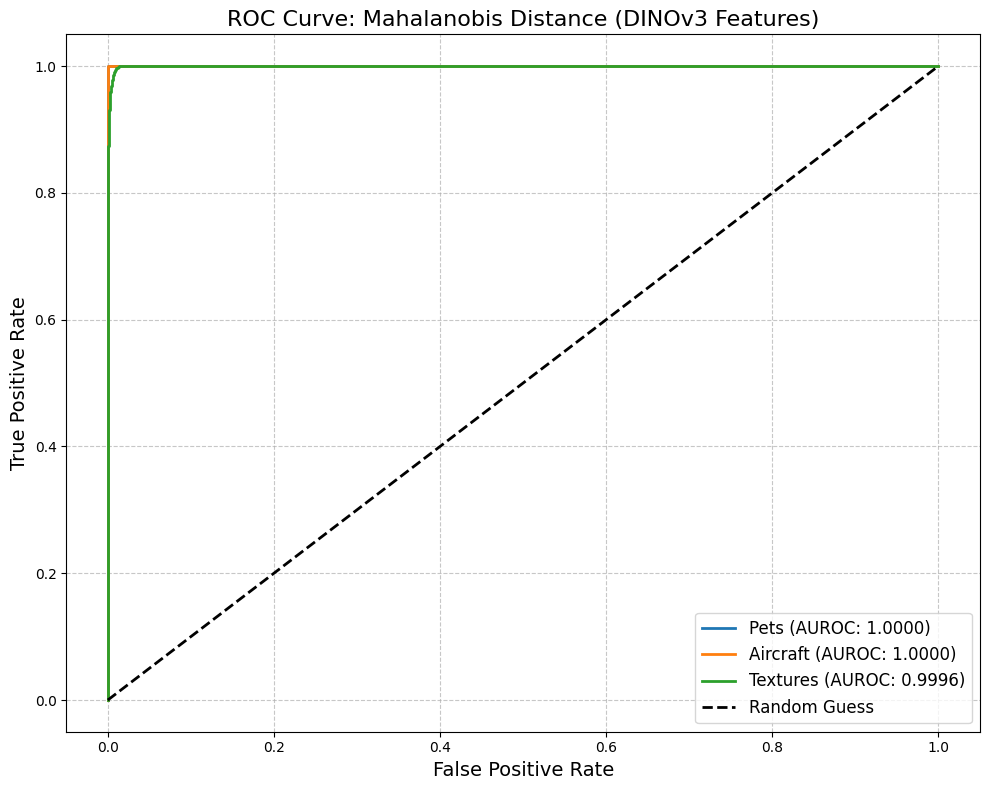

----------------------------------------
FINAL MAHALANOBIS AUROC RESULTS:
----------------------------------------
Food-101 vs Pets:     100.00%
Food-101 vs Aircraft: 100.00%
Food-101 vs Textures: 99.96%


In [118]:
plt.figure(figsize=(10, 8))
plt.plot(fpr_pets, tpr_pets, label=f'Pets (AUROC: {auroc_pets:.4f})', linewidth=2)
plt.plot(fpr_air, tpr_air, label=f'Aircraft (AUROC: {auroc_air:.4f})', linewidth=2)
plt.plot(fpr_tex, tpr_tex, label=f'Textures (AUROC: {auroc_tex:.4f})', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess', linewidth=2)

plt.title('ROC Curve: Mahalanobis Distance (DINOv3 Features)', fontsize=16)
plt.xlabel('False Positive Rate', fontsize=14)
plt.ylabel('True Positive Rate', fontsize=14)
plt.legend(loc='lower right', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("-" * 40)
print("FINAL MAHALANOBIS AUROC RESULTS:")
print("-" * 40)
print(f"Food-101 vs Pets:     {auroc_pets * 100:.2f}%")
print(f"Food-101 vs Aircraft: {auroc_air * 100:.2f}%")
print(f"Food-101 vs Textures: {auroc_tex * 100:.2f}%")